# Current manuscript figures

This notebook builds the proposed six-panel design: Figure 1 maps GCW relative to 2024 GDP; Figure 2 shows green-blue composition and 2024 accounting-balance transitions; Figure 3 shows forest-capacity erosion and its descriptive relationship with GCW.

Figure 4 is a coefficient plot for the three primary spatial relationships. It is generated only after the researcher completes the model-and-weight decision file. The notebook prepares and displays all candidate diagnostics and coefficient estimates without selecting a model.

## Regenerate the figures and spatial review from current outputs

The builder checks the agreed samples, uses updated GMW 2025 mangrove areas and 2024 socioeconomic data, and exports the spatial candidate dossier. It does not choose among spatial models or weights.

In [1]:
from pathlib import Path
import shutil
import subprocess
import sys

REPO = Path.cwd().resolve()
while not ((REPO / "data").is_dir() and (REPO / "code" / "scripts").is_dir()):
    if REPO == REPO.parent:
        raise FileNotFoundError("Run this notebook from the repository or one of its subfolders.")
    REPO = REPO.parent
BUILDER = REPO / "code" / "scripts" / "build_manuscript_artifacts.py"
PYTHON_EXECUTABLE = shutil.which("python") or sys.executable
print(f"Builder interpreter: {PYTHON_EXECUTABLE}")
result = subprocess.run(
    [PYTHON_EXECUTABLE, str(BUILDER), "--figures-only"],
    cwd=REPO, text=True, capture_output=True, check=False,
)
print(result.stdout)
if result.stderr:
    print(result.stderr)
if result.returncode:
    raise RuntimeError(f"Figure build failed with exit code {result.returncode}")
TABLES = REPO / "results" / "tables" / "manuscript"
FIGURES = REPO / "results" / "figures" / "manuscript"

Builder interpreter: C:\Users\aurel\AppData\Local\Programs\Python\Python311\python.EXE


('WARNING: ', 'ABW', ' is an island (no neighbors)')
('WARNING: ', 'AIA', ' is an island (no neighbors)')
('WARNING: ', 'ASM', ' is an island (no neighbors)')
('WARNING: ', 'ATG', ' is an island (no neighbors)')
('WARNING: ', 'AUS', ' is an island (no neighbors)')
('WARNING: ', 'BHR', ' is an island (no neighbors)')
('WARNING: ', 'BHS', ' is an island (no neighbors)')
('WARNING: ', 'BLM', ' is an island (no neighbors)')
('WARNING: ', 'BMU', ' is an island (no neighbors)')
('WARNING: ', 'BRB', ' is an island (no neighbors)')
('WARNING: ', 'COK', ' is an island (no neighbors)')
('WARNING: ', 'COM', ' is an island (no neighbors)')
('WARNING: ', 'CPV', ' is an island (no neighbors)')
('WARNING: ', 'CUB', ' is an island (no neighbors)')
('WARNING: ', 'CUW', ' is an island (no neighbors)')
('WARNING: ', 'CYM', ' is an island (no neighbors)')
('WARNING: ', 'CYP', ' is an island (no neighbors)')
('WARNING: ', 'DMA', ' is an island (no neighbors)')
('WARNING: ', 'FJI', ' is an island (no neighb

## Figures currently ready for review

Figure1_GCW_relative_to_GDP_2024.png


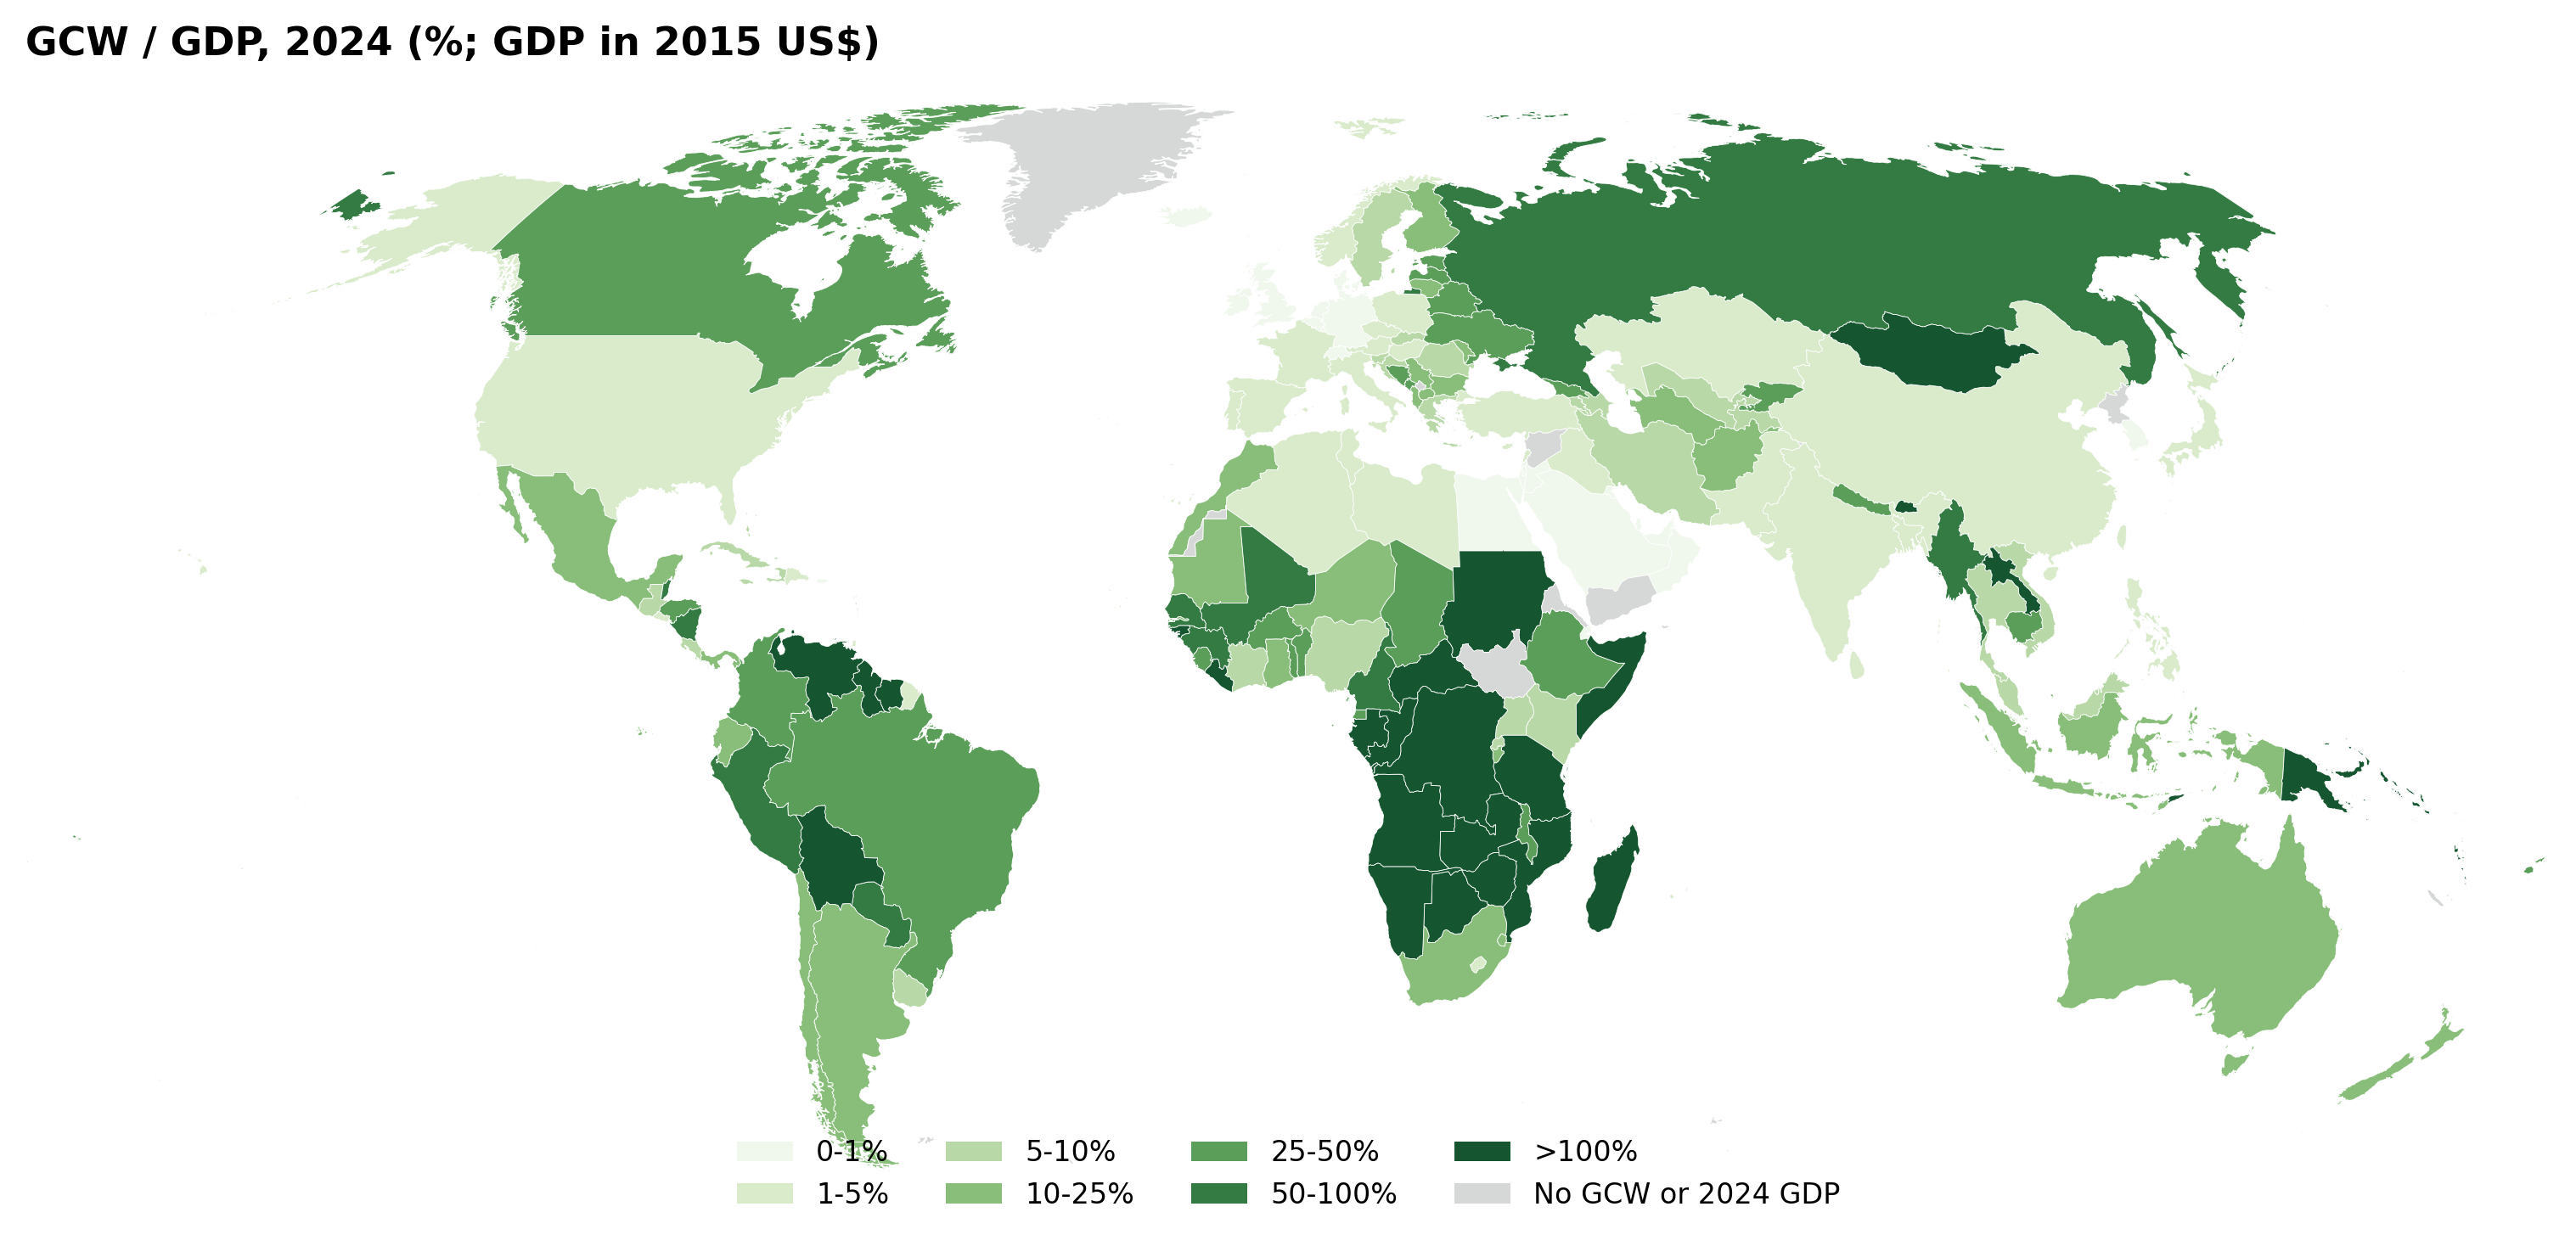

Figure2_marine_composition_and_balance_transitions.png


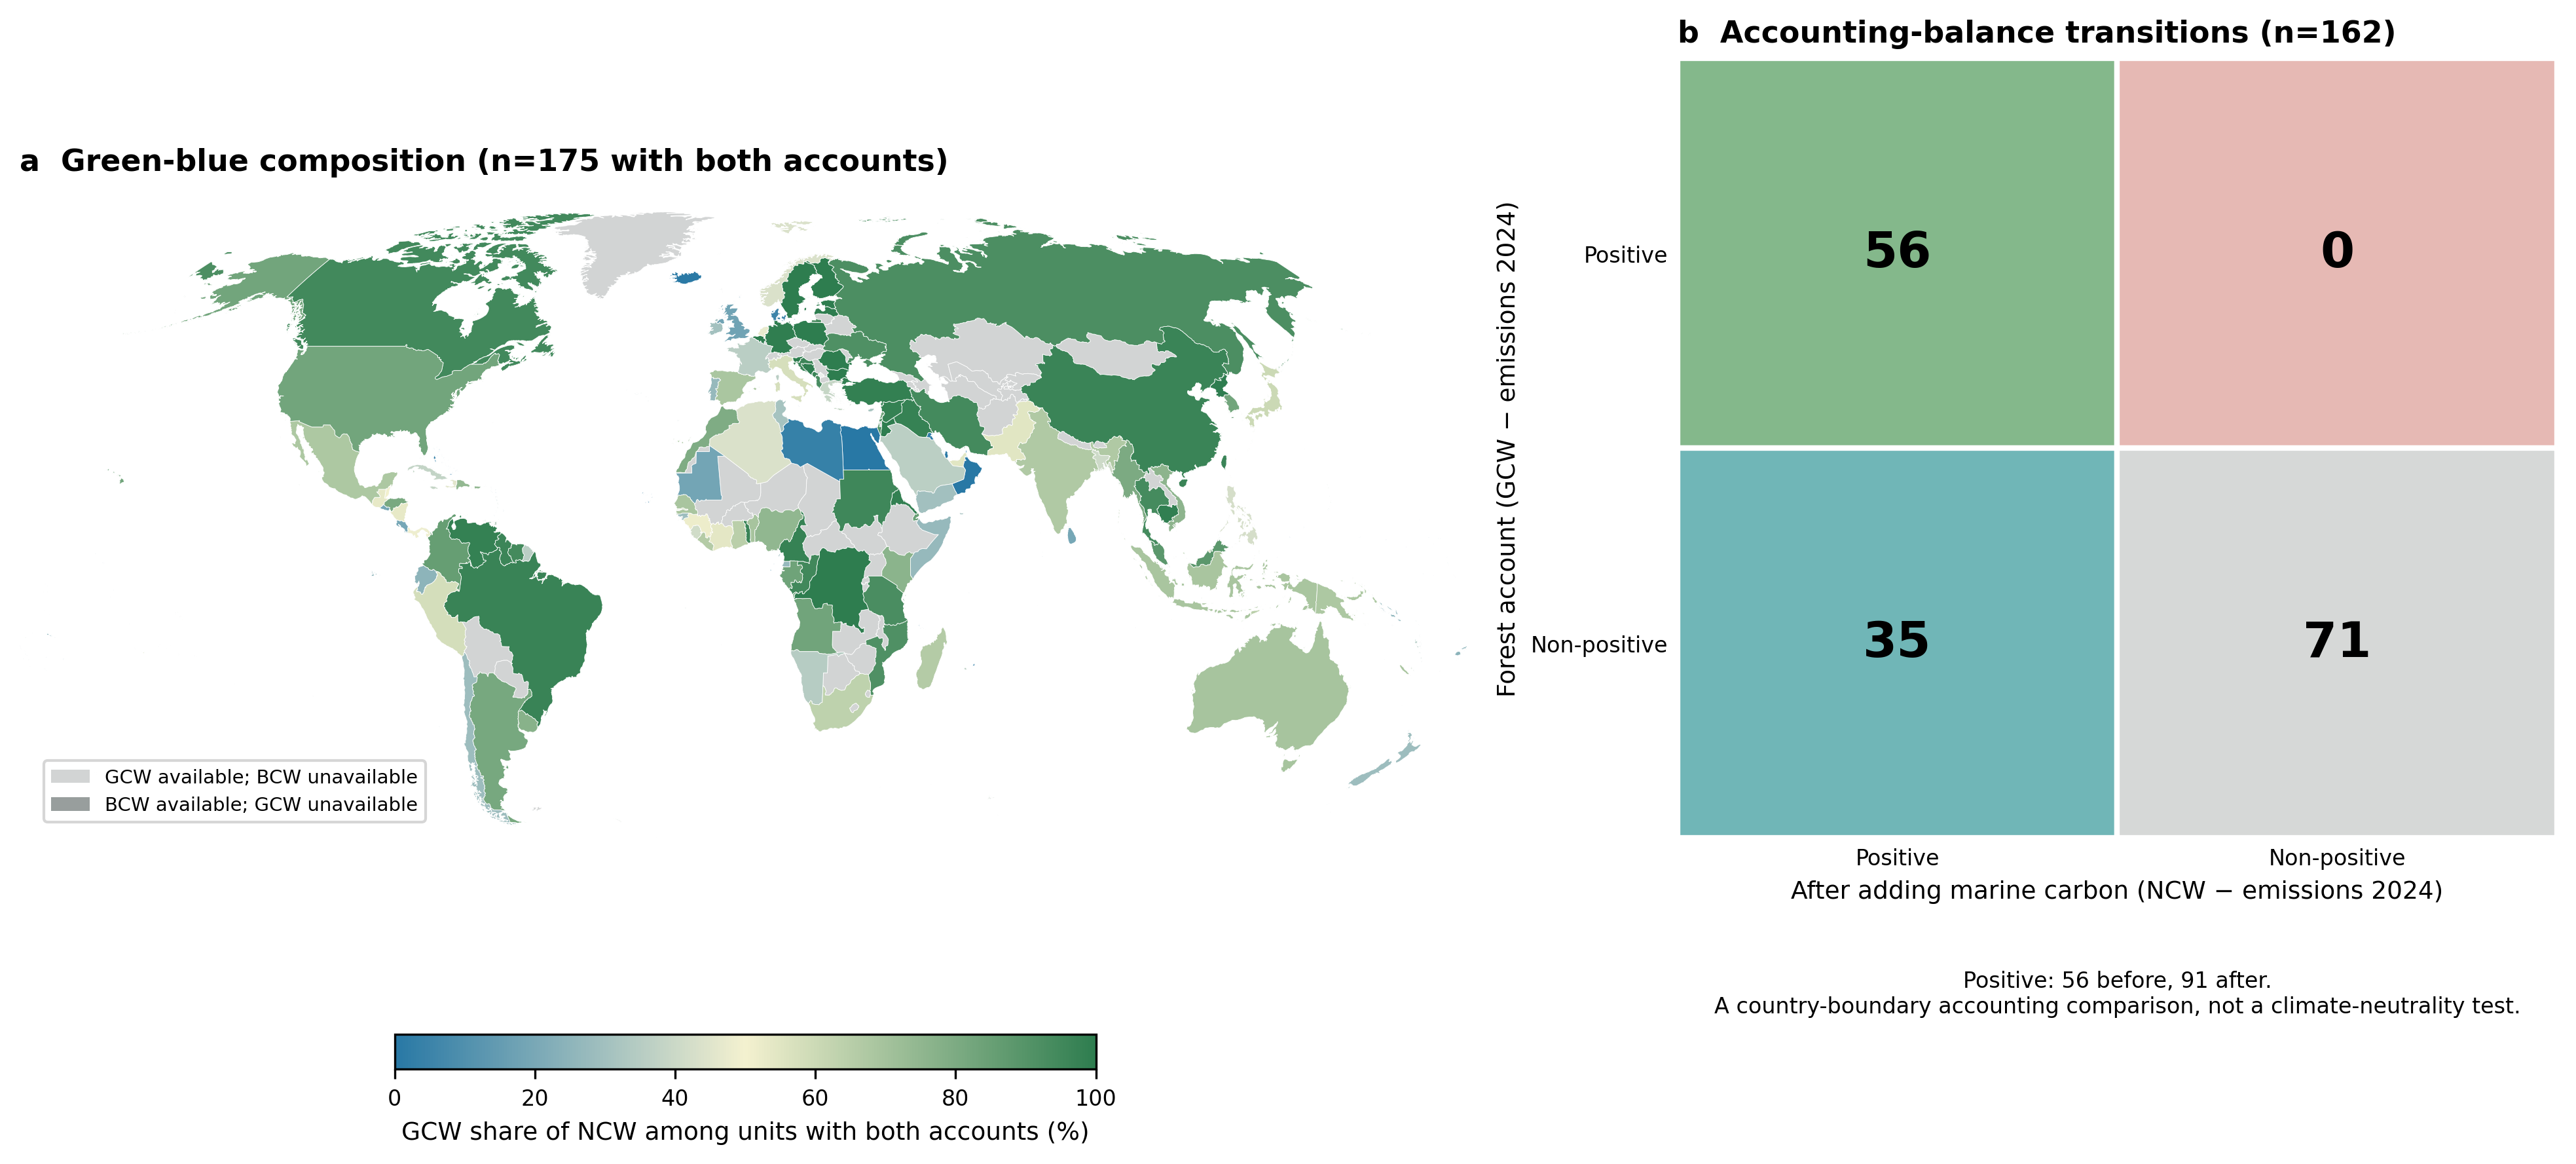

Figure3_forest_capacity_erosion.png


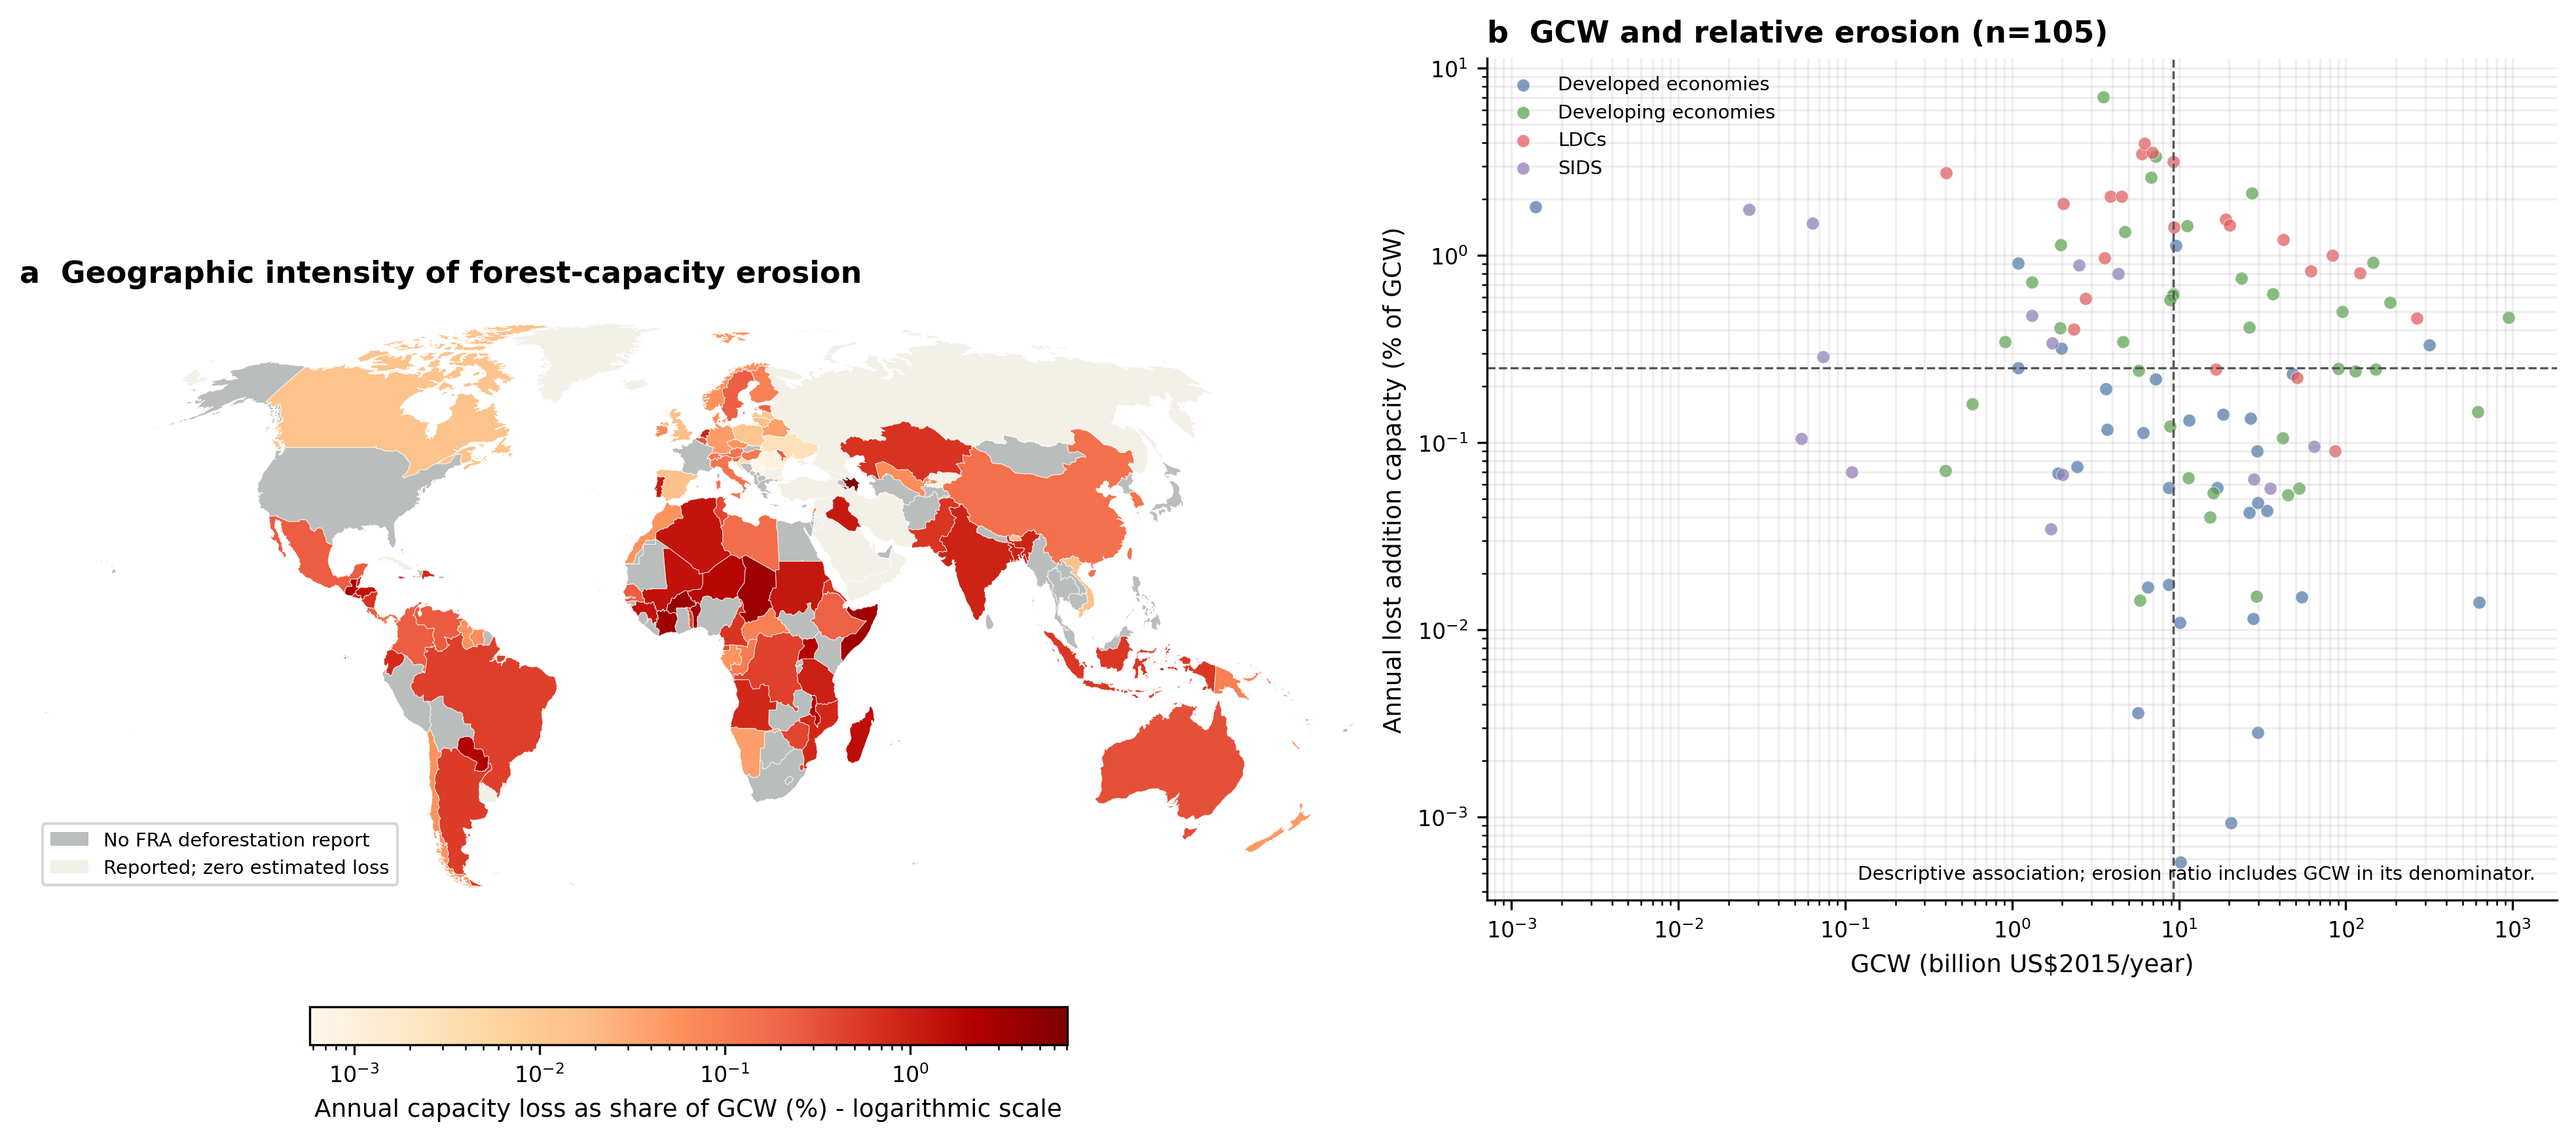

In [2]:
from IPython.display import Image, display

figure_files = [
    "Figure1_GCW_relative_to_GDP_2024.png",
    "Figure2_marine_composition_and_balance_transitions.png",
    "Figure3_forest_capacity_erosion.png",
]
for filename in figure_files:
    path = FIGURES / filename
    print(filename)
    display(Image(filename=str(path)))

## Figure 4 selection gate

Complete `results/validation/spatial_model_decision_template.csv` after reviewing the Moran, LM, nested LR and model-fit evidence. Copy the three primary decisions into `results/validation/manuscript_spatial_model_selection.csv`, with one row for each baseline outcome and columns `outcome`, `specification`, `weight`, and `model`. Re-run this notebook to create the coefficient plot. The final model/weight decision is not made by the builder.

In [3]:
import json
import pandas as pd
from IPython.display import Image, display

status_path = FIGURES / "Figure4_spatial_associations_status.json"
status = json.loads(status_path.read_text(encoding="utf-8"))
print(json.dumps(status, indent=2))
print("\nCandidate fits with the lowest BIC within each relationship and weight; these are comparisons, not final selections:")
dossier = pd.read_csv(TABLES / "Supplementary_spatial_selection_dossier.csv")
display(dossier.loc[dossier["bic_rank"].eq(1), ["relationship", "weight", "model", "aic", "bic", "n_fit"]].sort_values(["relationship", "weight"]))
print("\nResearcher decision template:")
display(pd.read_csv(REPO / "results" / "validation" / "spatial_model_decision_template.csv"))
if status["status"] == "ready_after_researcher_model_selection" and status["generated_file"]:
    display(Image(filename=str(FIGURES / status["generated_file"])))
else:
    print("Figure 4 is not generated until the three human model/weight choices are recorded.")

{
  "status": "pending_researcher_model_selection",
  "figure": "Figure 4 - coefficient plot for three selected spatial relationships",
  "generated_file": null,
  "candidate_contexts": 28,
  "contexts_flagged_selected_in_source": 0,
  "selection_manifest_expected": "results/validation/manuscript_spatial_model_selection.csv",
  "decision_template": "results/validation/spatial_model_decision_template.csv",
  "reason": "No final model/weight choices have been supplied. The selection dossier reports all diagnostics and candidate fits; the researcher must complete the decision template."
}

Candidate fits with the lowest BIC within each relationship and weight; these are comparisons, not final selections:


,relationship,weight,model,aic,bic,n_fit
0,Capacity-loss outcome,queen_contiguity,OLS,7.950131,21.887590,120
6,Capacity-loss outcome,symmetric_knn5,OLS,7.950131,21.887590,120
36,Capacity-loss outcome with emissions as X,queen_contiguity,OLS,9.182980,25.907931,120
42,Capacity-loss outcome with emissions as X,symmetric_knn5,OLS,9.182980,25.907931,120
96,Emissions outcome with GCW/GDP as X,queen_contiguity,SEM,505.463719,528.229633,191
102,Emissions outcome with GCW/GDP as X,symmetric_knn5,SEM,515.791708,538.557622,191
72,Emissions outcome with capacity loss as X,queen_contiguity,SEM,393.665204,413.177646,120
78,Emissions outcome with capacity loss as X,symmetric_knn5,SEM,411.106455,430.618898,120
84,Emissions outcome with relative erosion as X,queen_contiguity,SDEM,379.463442,410.125851,120
90,Emissions outcome with relative erosion as X,symmetric_knn5,SEM,410.419167,429.931609,120



Researcher decision template:


,relationship_order,relationship,role,specification,outcome,sample_n,minimum_bic_candidate_by_weight,final_model_decision,final_weight_decision,researcher_rationale,status
0,1,Capacity-loss outcome,Primary,baseline_2024_same_sample,lost_capacity_mtco2_yr,120,queen_contiguity: OLS (BIC=21.888); symmetric_...,NaN,NaN,NaN,Pending researcher choice
1,2,Relative-erosion outcome,Primary,baseline_2024_same_sample,erosion_pct_of_gcw,120,queen_contiguity: OLS (BIC=130.195); symmetric...,NaN,NaN,NaN,Pending researcher choice
2,3,GCW/GDP 2024 outcome,Primary,baseline_2024_same_sample,gcw_gdp_pct_2024,191,queen_contiguity: SDEM (BIC=575.648); symmetri...,NaN,NaN,NaN,Pending researcher choice
3,4,Capacity-loss outcome with emissions as X,Extended,add_emissions_2024_as_x,lost_capacity_mtco2_yr,120,queen_contiguity: OLS (BIC=25.908); symmetric_...,NaN,NaN,NaN,Pending researcher choice
4,5,Relative-erosion outcome with emissions as X,Extended,add_emissions_2024_as_x,erosion_pct_of_gcw,120,queen_contiguity: OLS (BIC=134.396); symmetric...,NaN,NaN,NaN,Pending researcher choice
5,6,GCW/GDP outcome with emissions as X,Extended,add_emissions_2024_as_x,gcw_gdp_pct_2024,191,symmetric_knn5: SEM (BIC=468.964); queen_conti...,NaN,NaN,NaN,Pending researcher choice
6,7,Emissions outcome with capacity loss as X,Extended,emissions_2024_as_y_plus_lost_capacity_x,emissions_mtco2_yr_2024,120,queen_contiguity: SEM (BIC=413.178); symmetric...,NaN,NaN,NaN,Pending researcher choice
7,8,Emissions outcome with relative erosion as X,Extended,emissions_2024_as_y_plus_erosion_x,emissions_mtco2_yr_2024,120,queen_contiguity: SDEM (BIC=410.126); symmetri...,NaN,NaN,NaN,Pending researcher choice
8,9,Emissions outcome with GCW/GDP as X,Extended,emissions_2024_as_y_plus_gcw_gdp_x,emissions_mtco2_yr_2024,191,queen_contiguity: SEM (BIC=528.230); symmetric...,NaN,NaN,NaN,Pending researcher choice


Figure 4 is not generated until the three human model/weight choices are recorded.


## Output directory

Current figure files are written to `results/figures/manuscript/`. Main tables and supplementary evidence are written to `results/tables/manuscript/` by the companion notebook.